*In all cases, written answers (apart from code) should not be longer than about three paragraphs.  Graders may not read all of your
submission if it is longer than that.*

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

import os
from scipy import stats

##### **HW Reflection #1**

1. In Coding Quiz 1, you are asked to find the distance of the farthest match in a set.  Is this farthest match distance too far to be a meaningful match?  How can you decide this? **(Worded) (Q4, Q5)**

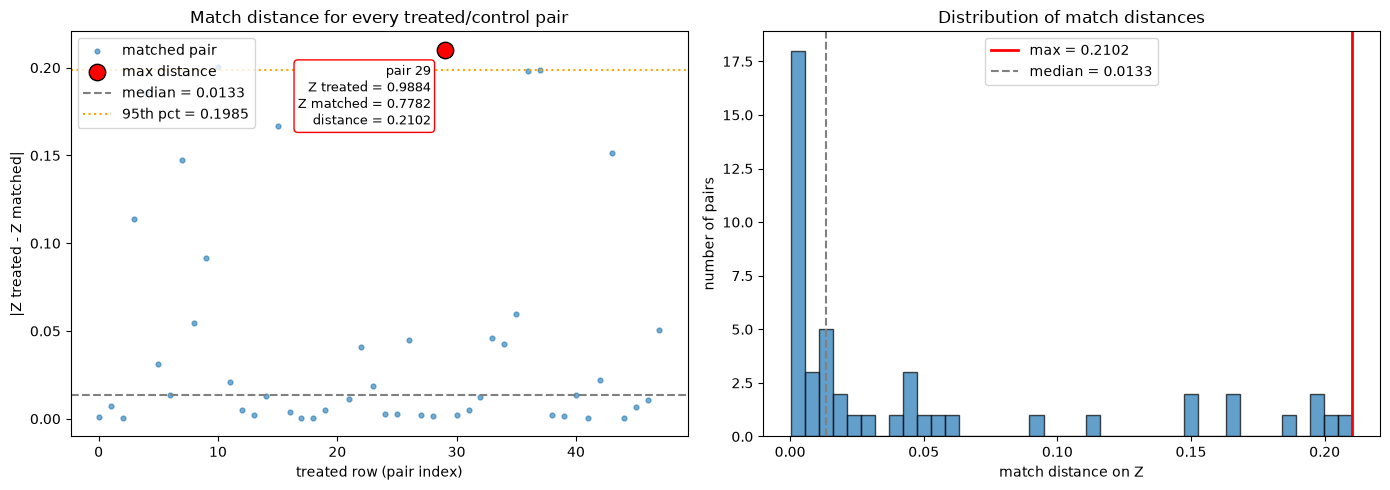

columns: X=X, Z=Z, Y=Y
treated: 48, control: 52, pairs: 48
max distance: 0.210217 (pair 29)
max is 15.9x the median distance
max distance = 0.79 SDs of Z

max pair:
Z_treated         0.988374
Z_matched         0.778157
match_distance    0.210217
Y_treated         1.488374
Y_matched         0.778157
Name: 29, dtype: float64


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

mat_df = pd.read_csv("homework_1.2.csv")

def is_binary(s):
    v = pd.to_numeric(s, errors="coerce").dropna().unique()
    return set(np.round(v, 12)) <= {0.0, 1.0}

binary_cols = [c for c in mat_df.columns if is_binary(mat_df[c])]
TREAT  = next((c for c in mat_df.columns if c.strip().upper() == "X"), binary_cols[0])
MATCHV = next((c for c in mat_df.columns if c.strip().upper() == "Z"), None)
OUTY   = next((c for c in mat_df.columns if c.strip().upper() == "Y"), None)

rest = [c for c in mat_df.columns if c not in {TREAT, MATCHV, OUTY}]
if MATCHV is None:
    MATCHV = rest.pop(0)
if OUTY is None:
    OUTY = rest.pop(0)

m = mat_df[[TREAT, MATCHV, OUTY]].dropna().reset_index(drop=True)
treated = m[m[TREAT] == 1].reset_index(drop=True)
control = m[m[TREAT] == 0].reset_index(drop=True)

z_t = treated[MATCHV].to_numpy(float)
z_c = control[MATCHV].to_numpy(float)

order = np.argsort(z_c)
zs = z_c[order]
pos = np.clip(np.searchsorted(zs, z_t), 1, len(zs) - 1)
take_left = np.abs(z_t - zs[pos - 1]) <= np.abs(zs[pos] - z_t)
match_idx = order[np.where(take_left, pos - 1, pos)]
dist = np.abs(z_t - z_c[match_idx])

pairs = pd.DataFrame({
    f"{MATCHV}_treated": z_t,
    f"{MATCHV}_matched": z_c[match_idx],
    "match_distance":    dist,
    f"{OUTY}_treated":   treated[OUTY].to_numpy(),
    f"{OUTY}_matched":   control[OUTY].to_numpy()[match_idx],
})

d = pairs["match_distance"]
i_max = d.idxmax()
row = pairs.loc[i_max]
right_side = i_max > len(d) / 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(pairs.index, d, s=12, alpha=0.6, label="matched pair")
ax1.scatter(i_max, d[i_max], s=140, color="red", edgecolor="black", zorder=3,
            label="max distance")
ax1.axhline(d.median(), ls="--", color="gray", label=f"median = {d.median():.4f}")
ax1.axhline(d.quantile(0.95), ls=":", color="orange",
            label=f"95th pct = {d.quantile(0.95):.4f}")
ax1.annotate(
    f"pair {i_max}\n"
    f"{MATCHV} treated = {row[f'{MATCHV}_treated']:.4f}\n"
    f"{MATCHV} matched = {row[f'{MATCHV}_matched']:.4f}\n"
    f"distance = {d[i_max]:.4f}",
    xy=(i_max, d[i_max]), xytext=(-10 if right_side else 10, -10),
    textcoords="offset points", ha="right" if right_side else "left",
    va="top", fontsize=9, bbox=dict(boxstyle="round", fc="white", ec="red"))
ax1.set_xlabel("treated row (pair index)")
ax1.set_ylabel(f"|{MATCHV} treated - {MATCHV} matched|")
ax1.set_title("Match distance for every treated/control pair")
ax1.legend(loc="upper left")

ax2.hist(d, bins=40, edgecolor="black", alpha=0.7)
ax2.axvline(d[i_max], color="red", lw=2, label=f"max = {d[i_max]:.4f}")
ax2.axvline(d.median(), color="gray", ls="--", label=f"median = {d.median():.4f}")
ax2.set_xlabel(f"match distance on {MATCHV}")
ax2.set_ylabel("number of pairs")
ax2.set_title("Distribution of match distances")
ax2.legend()

plt.tight_layout()
plt.show()

z_sd = treated[MATCHV].std()
print(f"columns: X={TREAT}, Z={MATCHV}, Y={OUTY}")
print(f"treated: {len(treated)}, control: {len(control)}, pairs: {len(pairs)}")
print(f"max distance: {d[i_max]:.6f} (pair {i_max})")
print(f"max is {d[i_max] / d.median():.1f}x the median distance")
print(f"max distance = {d[i_max] / z_sd:.2f} SDs of {MATCHV}")
print("\nmax pair:")
print(row)

> **Answer:** </p> The distance of the farthest match was ~0.21. If you compare it on a percentile score, it lies above the 95% of all the other data. However, compared to the standard deviation of variable Z, its less than one. The senstivity of accepting this distance would depend on the goal of an experiement using this method. The distance 0.21 could be too much for a drug/pharma research study with serious health risk implications. The research team would have to be cautious if publishing a matching distance that is 15x the median distance of other observations could mean less certainty in the expected outcomes.

2. In Coding Quiz 1, there are two approaches to matching: 
</p> (A) Picking the best match X = 0 corresponding to each X = 1 using Z values.
</p> (B) Using radius_neighbors to pick all matches X = 0 within a distance of 0.2 of each X = 1.

Invent your own type of matching similar to 1 and 2 (or look one up on the internet), which has a different way to pick the matches in X = 0.  Clearly explain the approach you invented or found. **(Worded) (Q4, Q5, Q6, Q7)**

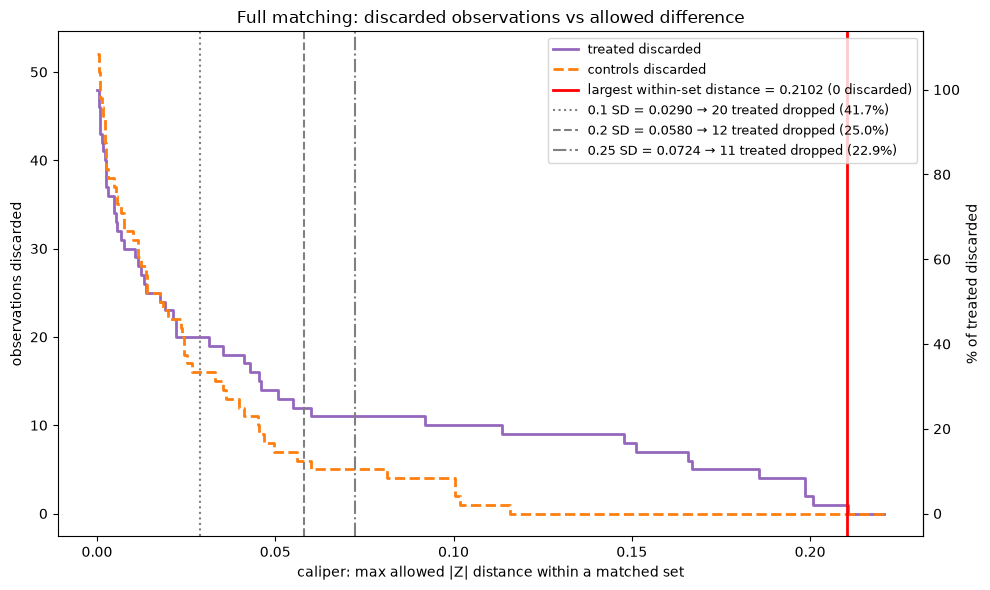

columns: X=X, Z=Z, Y=Y
treated: 48, control: 52, matched sets: 22
set sizes: 2 to 19 units
total |Z| distance: 3.6142
full-matching ATT estimate (no caliper): 0.545228



,caliper_SD,caliper_value,treated_discarded,controls_discarded,pct_treated_discarded
0,0.10,0.0290,20,16,41.67
1,0.20,0.0580,12,6,25.00
2,0.25,0.0724,11,5,22.92


In [ ]:
CALIPERS_SD = [0.1, 0.2, 0.25] 

mat_df = pd.read_csv("homework_1.2.csv")

def is_binary(s):
    v = pd.to_numeric(s, errors="coerce").dropna().unique()
    return set(np.round(v, 12)) <= {0.0, 1.0}

binary_cols = [c for c in mat_df.columns if is_binary(mat_df[c])]
TREAT  = next((c for c in mat_df.columns if c.strip().upper() == "X"), binary_cols[0])
MATCHV = next((c for c in mat_df.columns if c.strip().upper() == "Z"), None)
OUTY   = next((c for c in mat_df.columns if c.strip().upper() == "Y"), None)

rest = [c for c in mat_df.columns if c not in {TREAT, MATCHV, OUTY}]
if MATCHV is None:
    MATCHV = rest.pop(0)
if OUTY is None:
    OUTY = rest.pop(0)

m = mat_df[[TREAT, MATCHV, OUTY]].dropna().reset_index(drop=True)
z_sd = m[MATCHV].std()

order = np.argsort(m[MATCHV].to_numpy(float), kind="mergesort")
zs = m[MATCHV].to_numpy(float)[order]
xs = m[TREAT].to_numpy(int)[order]
ys = m[OUTY].to_numpy(float)[order]
n = len(zs)

cnt = {g: np.concatenate([[0], np.cumsum(xs == g)]) for g in (0, 1)}
sm  = {g: np.concatenate([[0], np.cumsum(np.where(xs == g, zs, 0.0))]) for g in (0, 1)}

def star_cost(j, i, k):
    """Total |Z distance| from center unit k to every other unit in sorted range [j, i)."""
    o, c = 1 - xs[k], zs[k]
    nl, sl = cnt[o][k] - cnt[o][j], sm[o][k] - sm[o][j]
    nr, sr = cnt[o][i] - cnt[o][k + 1], sm[o][i] - sm[o][k + 1]
    return c * nl - sl + sr - c * nr

best = np.full(n + 1, np.inf); best[0] = 0.0
back = np.zeros(n + 1, int)
ctr  = np.zeros(n + 1, int)

for i in range(1, n + 1):
    nt = nc = 0
    last_t = last_c = -1
    for j in range(i - 1, -1, -1):
        if xs[j] == 1:
            nt += 1; last_t = j
        else:
            nc += 1; last_c = j
        if nt >= 2 and nc >= 2:
            break
        if nt == 0 or nc == 0 or not np.isfinite(best[j]):
            continue
        k = last_t if nt == 1 else last_c     
        cost = best[j] + star_cost(j, i, k)
        if cost < best[i]:
            best[i], back[i], ctr[i] = cost, j, k

if not np.isfinite(best[n]):
    raise ValueError("Full matching failed: need at least one treated and one control unit.")

set_id = np.empty(n, int)
center = np.empty(n, int)
i, s = n, 0
while i > 0:
    j = back[i]
    set_id[j:i], center[j:i] = s, ctr[i]
    i, s = j, s + 1

units = pd.DataFrame({
    "set": set_id, "z": zs, "x": xs, "y": ys,
    "dist": np.abs(zs - zs[center]),
    "is_center": np.arange(n) == center,
})

min_partner = units[~units["is_center"]].groupby("set")["dist"].min()
units["keep_at"] = np.where(units["is_center"], units["set"].map(min_partner), units["dist"])

sets = units.groupby("set").agg(n_treated=("x", "sum"), n_units=("x", "size"),
                                max_dist=("dist", "max"))
sets["n_control"] = sets["n_units"] - sets["n_treated"]
y_means = units.groupby(["set", "x"])["y"].mean().unstack()
sets["dY"] = y_means[1] - y_means[0]
att = (sets["n_treated"] * sets["dY"]).sum() / sets["n_treated"].sum()

keep_t = np.sort(units.loc[units["x"] == 1, "keep_at"])
keep_c = np.sort(units.loc[units["x"] == 0, "keep_at"])
n_t, n_c = len(keep_t), len(keep_c)
worst = units["keep_at"].max()

thresholds = np.linspace(0, worst * 1.05, 500)
drop_t = n_t - np.searchsorted(keep_t, thresholds, side="right")
drop_c = n_c - np.searchsorted(keep_c, thresholds, side="right")

fig, ax = plt.subplots(figsize=(10, 6))
ax.step(thresholds, drop_t, where="post", lw=2, color="tab:purple", label="treated discarded")
ax.step(thresholds, drop_c, where="post", lw=2, color="tab:orange", ls="--",
        label="controls discarded")
ax.axvline(worst, color="red", lw=2, label=f"largest within-set distance = {worst:.4f} (0 discarded)")
for c_sd, ls in zip(CALIPERS_SD, [":", "--", "-."]):
    c = c_sd * z_sd
    n_drop = int((keep_t > c).sum())
    ax.axvline(c, color="gray", ls=ls,
               label=f"{c_sd} SD = {c:.4f} → {n_drop} treated dropped ({n_drop / n_t:.1%})")
ax.set_xlabel(f"caliper: max allowed |{MATCHV}| distance within a matched set")
ax.set_ylabel("observations discarded")
ax.set_title("Full matching: discarded observations vs allowed difference")
sec = ax.secondary_yaxis("right", functions=(lambda v: v / n_t * 100, lambda p: p * n_t / 100))
sec.set_ylabel("% of treated discarded")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"columns: X={TREAT}, Z={MATCHV}, Y={OUTY}")
print(f"treated: {n_t}, control: {n_c}, matched sets: {len(sets)}")
print(f"set sizes: {sets['n_units'].min()} to {sets['n_units'].max()} units")
print(f"total |{MATCHV}| distance: {best[n]:.4f}")
print(f"full-matching ATT estimate (no caliper): {att:.6f}\n")

cal_table = pd.DataFrame({"caliper_SD": CALIPERS_SD,
                          "caliper_value": [c * z_sd for c in CALIPERS_SD]})
cal_table["treated_discarded"] = [int((keep_t > v).sum()) for v in cal_table["caliper_value"]]
cal_table["controls_discarded"] = [int((keep_c > v).sum()) for v in cal_table["caliper_value"]]
cal_table["pct_treated_discarded"] = (cal_table["treated_discarded"] / n_t * 100).round(2)
display(cal_table.round(4))

> **Answer:** </p> My method would used all possible combinations and compare how many observations to drop based on the average distanced for all matched sets. In the plot above, 0.2 standard deviations of Z means 1/4 of the dataset is removed since the average distance is too great. This method focuses more on what the end result is being the distance rather than the matching itself. This could work best with small datasets.  

##### **HW Reflection #2**

1. Invent an example situation that would use fixed effects. **(Worded)**

> **Answer:** </p> A car company wants to determine if certain the material in a tire affects fuel efficiency for a new flagship car model based on older models. The general regression model might look like: density of tire material (slope) x miles + engine (intercept) = remaining fuel. The baseline (engine) differs between older models since newer ones are assumed to be more efficient. 

2. Write a Python program that performs a bootstrap simulation to find the variance in the mean of the Pareto distribution when different samples are taken.  Explain what you had to do for this.  As you make the full sample size bigger (for the same distribution), what happens to the variance of the mean of the samples?  Does it stay about the same, get smaller, or get bigger? **(Code and Worded)**

> **Answer:** </p> When doing bootstraping simulation, as the sample sizes increase the variance of the mean of the samples gets smaller and smaller. On a Pareto distribution the variance would be seen decreasing for each randomly choosen sample.

   trip_id     model  miles
0        1  Flagship  111.4
1        2  Flagship  108.9
2        3  Flagship  110.7
3        4  Flagship   54.9
4        5  Flagship   51.5 

sample mean: 71.12 miles
bootstrap variance of the mean (n=30): 17.11

      n  bootstrap_var  theory_var (sigma^2/n)
0    10         26.220                 187.500
1    30         17.321                  62.500
2   100          9.176                  18.750
3   300          4.816                   6.250
4  1000          1.194                   1.875
5  3000          0.589                   0.625


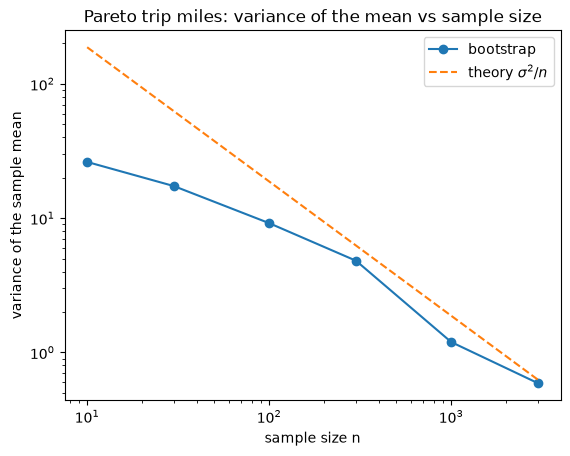

In [ ]:
rng = np.random.default_rng(42)
ALPHA, XM = 3.0, 50 

def make_trips(n):
    """Fictional trip distances (miles) for the flagship car, Pareto(ALPHA, XM)."""
    return XM * (1 + rng.pareto(ALPHA, n))

def bootstrap_means(x, B=2000):
    """Resample x with replacement B times and return the mean of each resample."""
    return rng.choice(x, size=(B, len(x)), replace=True).mean(axis=1)

trips = pd.DataFrame({"trip_id": range(1, 31), "model": "Flagship",
                      "miles": make_trips(30).round(1)})
print(trips.head(), "\n")

means = bootstrap_means(trips["miles"].to_numpy())
print(f"sample mean: {trips['miles'].mean():.2f} miles")
print(f"bootstrap variance of the mean (n=30): {means.var(ddof=1):.2f}\n")

true_var = XM**2 * ALPHA / ((ALPHA - 1)**2 * (ALPHA - 2))  
sizes = [10, 30, 100, 300, 1000, 3000]
results = pd.DataFrame({"n": sizes})
results["bootstrap_var"] = [bootstrap_means(make_trips(n)).var(ddof=1) for n in sizes]
results["theory_var (sigma^2/n)"] = true_var / results["n"]
print(results.round(3))

plt.loglog(results["n"], results["bootstrap_var"], "o-", label="bootstrap")
plt.loglog(results["n"], results["theory_var (sigma^2/n)"], "--", label=r"theory $\sigma^2/n$")
plt.xlabel("sample size n")
plt.ylabel("variance of the sample mean")
plt.title("Pareto trip miles: variance of the mean vs sample size")
plt.legend()
plt.show()

##### **HW Reflection #3**

1. In the event study in Coding Quiz 3, how would we go about testing for a change in the second derivative as well? **(Worded)**

> **Answer:** </p> To test for a change in the second derivative, we add a squared time term to a regression assuming a discontinuity, along with that squared term multiplied by $\text{post}$, a dummy equal to 1 at or after the event ($t \ge 50$) and 0 before it:

$$
y_t = \beta_0 + \beta_1(t-50) + \beta_2\,\text{post} + \beta_3\,\text{post}\,(t-50) + \beta_4(t-50)^2 + \beta_5\,\text{post}\,(t-50)^2 + \varepsilon_t
$$

If the p-value for $\beta_5$ is below 0.05, the second derivative changed at $t = 50$.

**Summary:**
- $\text{post}$: 1 after the event, 0 before
- $\beta_2$: jump in the value
- $\beta_3$: change in the slope
- $\beta_4$: curvature before the event
- $\beta_5$: change in curvature after the event (significant if $p < 0.05$)

2. Create your own scenario that illustrates differences-in-differences. Describe the story behind the data and show whether there is a nonzero treatment effect. **(Worded)**

> **Answer:** </p> A car company tests a new tire material to see if it improves fuel efficiency. The new tires are put on the flagship model (the **treatment group**), while an older model keeps its original tires (the **control group**). Fuel efficiency (miles per gallon) is recorded for both models before and after the new tires are introduced.

| Group | Before (mpg) | After (mpg) | Change |
|---|---|---|---|
| Flagship (new tires) | 30 | 34 | +4 |
| Older model (original tires) | 28 | 29 | +1 |

Both models improved a little after the switch, possibly because of seasonal factors such as warmer weather, which affect every car. The control group's change (+1 mpg) captures this shared trend. Subtracting it from the treatment group's change isolates the effect of the tires:

$$
\text{Treatment effect} = (34 - 30) - (29 - 28) = 4 - 1 = 3 \text{ mpg}
$$

In the regression $Y = \beta_0 + \beta_1\,\text{treat} + \beta_2\,\text{post} + \beta_3(\text{treat} \times \text{post}) + \varepsilon$, this is $\beta_3 = 3$. If its p-value is below 0.05, there is a nonzero treatment effect: the new tire material improves fuel efficiency by about 3 mpg. This relies on the **parallel-trends assumption**, that without the new tires, both models would have improved by the same amount.

##### **HW Reflection #4**

1. The Coding Quiz gives two options for instrumental variables.  For the second item (dividing the range of W into multiple ranges), explain how you did it, show your code, and discuss any issues you encountered. **(Coded and Worded)**

> **Answer:** </p> I divided the dataset into 10 bands of 500 observations each then applied the equation presented in the lesson (aka the wald ratio) to each band independently.

In [ ]:
CSV_IV = "homework_4.1.csv"    
N_BINS = 10                        

pd.set_option("display.float_format", lambda v: f"{v:,.6f}")

def find_file(*candidates):
  
    for c in candidates:
        if os.path.exists(c):
            return c
    raise FileNotFoundError(f"none of these exist: {candidates}")

iv = pd.read_csv(CSV_IV)
iv.head()

def pick(df, letter, fallback_pool):
    hit = next((c for c in df.columns if c.strip().upper() == letter), None)
    return hit if hit is not None else fallback_pool.pop(0)

pool = list(iv.columns)
XT = pick(iv, "X", pool)   # treatment
WC = pick(iv, "W", pool)   # confounder
YO = pick(iv, "Y", pool)   # outcome
ZI = pick(iv, "Z", pool)   # instrument

print(f"treatment  X -> {XT}")
print(f"confounder W -> {WC}")
print(f"outcome    Y -> {YO}")
print(f"instrument Z -> {ZI}")

d = iv[[XT, WC, YO, ZI]].dropna().reset_index(drop=True)
print(f"\nn = {len(d)}")
print(f"{ZI} takes values: {sorted(d[ZI].unique())[:10]}")
print(f"{XT} takes values: {sorted(d[XT].unique())[:10]}")
d.groupby(ZI)[[XT, WC, YO]].agg(["mean", "count"]) 

def stratified_wald(data, n_bins, min_dx=1e-3, weighted=False, verbose=True):
    work = data.copy()
    work["W_band"] = pd.qcut(work[WC], q=n_bins, duplicates="drop")

    rows = []
    for band, g in work.groupby("W_band", observed=True):
        g1, g0 = g[g[ZI] == 1], g[g[ZI] == 0]
        if len(g1) == 0 or len(g0) == 0:
            rows.append({"band": band, "n": len(g), "n_z1": len(g1), "n_z0": len(g0),
                         "dY": np.nan, "dX": np.nan, "ratio": np.nan, "used": False})
            continue
        dy = g1[YO].mean() - g0[YO].mean()
        dx = g1[XT].mean() - g0[XT].mean()
        ok = abs(dx) > min_dx
        rows.append({"band": band, "n": len(g), "n_z1": len(g1), "n_z0": len(g0),
                     "dY": dy, "dX": dx, "ratio": dy / dx if ok else np.nan, "used": ok})

    table = pd.DataFrame(rows)
    good = table[table["used"]]
    simple = good["ratio"].mean()
    wtd = np.average(good["ratio"], weights=good["n"]) if len(good) else np.nan

    if verbose:
        print(f"{len(good)} of {len(table)} bands usable")
        print(f"simple average of the band ratios   : {simple:.6f}")
        print(f"size-weighted average               : {wtd:.6f}")
        print(f"median band ratio                   : {good['ratio'].median():.6f}")
    return (wtd if weighted else simple), table

wald_stratified, band_table = stratified_wald(d, 10)
print(f"\n>>> Q2  effect averaged over {N_BINS} bands of {WC} = {wald_stratified:.6f}")
band_table

treatment  X -> X
confounder W -> W
outcome    Y -> Y
instrument Z -> Z

n = 5000
Z takes values: [np.int64(0), np.int64(1)]
X takes values: [np.float64(-3.40408421), np.float64(-3.311210588), np.float64(-3.25903156), np.float64(-3.139951666), np.float64(-3.026192467), np.float64(-3.015274809), np.float64(-2.83197146), np.float64(-2.785460151), np.float64(-2.766048901), np.float64(-2.645544573)]
10 of 10 bands usable
simple average of the band ratios   : 1.508896
size-weighted average               : 1.508896
median band ratio                   : 1.532339

>>> Q2  effect averaged over 10 bands of W = 1.508896


,band,n,n_z1,n_z0,dY,dX,ratio,used
0,"(-3.304, -1.277]",500,238,262,1.607540,1.044030,1.539745,True
1,"(-1.277, -0.855]",500,249,251,1.297084,0.986141,1.315313,True
2,"(-0.855, -0.547]",500,238,262,1.580719,0.982420,1.609005,True
3,"(-0.547, -0.277]",500,260,240,1.425240,0.880740,1.618229,True
4,"(-0.277, -0.0322]",500,250,250,1.457033,0.999155,1.458265,True
5,"(-0.0322, 0.226]",500,242,258,1.659027,1.078625,1.538094,True
6,"(0.226, 0.491]",500,255,245,1.983408,1.237388,1.602899,True
7,"(0.491, 0.814]",500,248,252,1.441386,0.970424,1.485316,True
8,"(0.814, 1.303]",500,265,235,1.589708,1.041350,1.526583,True
9,"(1.303, 4.783]",500,262,238,1.347548,0.965628,1.395514,True


2. Plot the college outcome (Y) vs. the test score (X) in a small range of test scores around 80. On the plot, compare it with the Y probability predicted by logistic regression. The ground truth Y value is 0 or 1; don't just plot 0 or 1 - that will make it unreadable.  Find some way to make it look better than that. **(Coded and Worded)**

          Coef.  Std.Err.           z  P>|z|    [0.025    0.975]
const -6.915550  0.074112  -93.312592    0.0 -7.060806 -6.770294
X2     0.105616  0.000975  108.292128    0.0  0.103705  0.107528


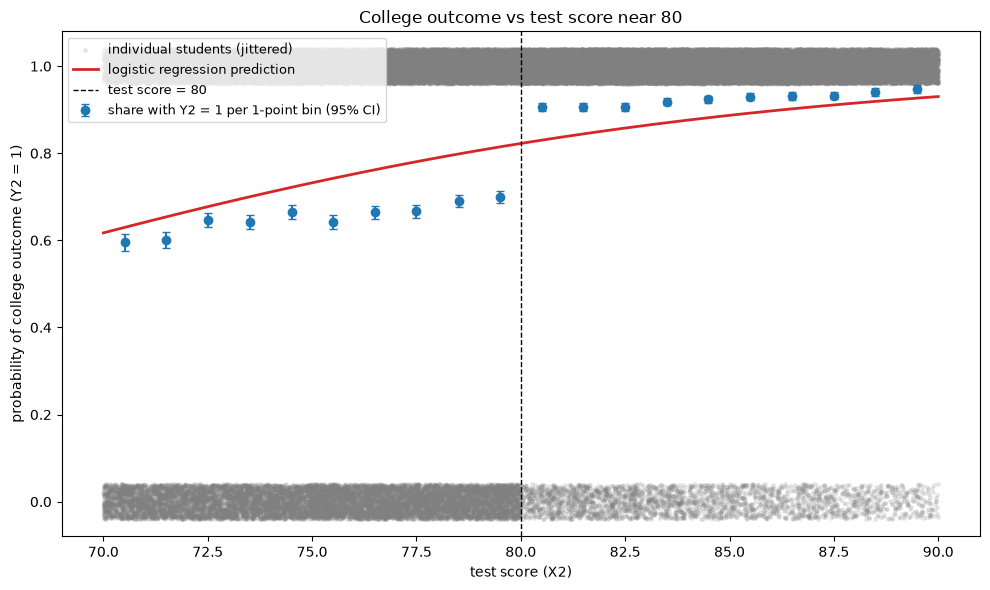


students in window: 68139


,x_mid,p,n,se
bin,,,,
"(69.999, 71.0]",70.508,0.595,2491,0.010
"(71.0, 72.0]",71.507,0.601,2669,0.009
"(72.0, 73.0]",72.504,0.647,3078,0.009
"(73.0, 74.0]",73.512,0.642,3129,0.009
"(74.0, 75.0]",74.508,0.665,3417,0.008
"(75.0, 76.0]",75.502,0.642,3678,0.008
"(76.0, 77.0]",76.504,0.665,3769,0.008
"(77.0, 78.0]",77.501,0.667,3746,0.008
"(78.0, 79.0]",78.509,0.691,4038,0.007


In [ ]:
CENTER, HALF_WIDTH, BIN_WIDTH = 80, 10, 1 

df = pd.read_csv("homework_4.2.b.csv")
XCOL = next((c for c in df.columns if c.strip().upper() == "X"), df.columns[0])
YCOL = next((c for c in df.columns if c.strip().upper() == "Y"), df.columns[1])
df = df[[XCOL, YCOL]].dropna()

logit = sm.Logit(df[YCOL], sm.add_constant(df[XCOL])).fit(disp=0)
print(logit.summary2().tables[1])

win = df[df[XCOL].between(CENTER - HALF_WIDTH, CENTER + HALF_WIDTH)].copy()
edges = np.arange(CENTER - HALF_WIDTH, CENTER + HALF_WIDTH + BIN_WIDTH, BIN_WIDTH)
win["bin"] = pd.cut(win[XCOL], edges, include_lowest=True)

binned = win.groupby("bin", observed=True).agg(x_mid=(XCOL, "mean"),
                                               p=(YCOL, "mean"),
                                               n=(YCOL, "size"))
binned["se"] = np.sqrt(binned["p"] * (1 - binned["p"]) / binned["n"])

x_grid = np.linspace(CENTER - HALF_WIDTH, CENTER + HALF_WIDTH, 300)
p_grid = logit.predict(sm.add_constant(pd.Series(x_grid, name=XCOL)))

rng = np.random.default_rng(0)
jitter_y = win[YCOL] + rng.uniform(-0.04, 0.04, len(win))

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(win[XCOL], jitter_y, s=6, alpha=0.15, color="gray", label="individual students (jittered)")
ax.errorbar(binned["x_mid"], binned["p"], yerr=1.96 * binned["se"], fmt="o", color="tab:blue",
            capsize=3, label=f"share with {YCOL} = 1 per {BIN_WIDTH}-point bin (95% CI)")
ax.plot(x_grid, p_grid, color="tab:red", lw=2, label="logistic regression prediction")
ax.axvline(CENTER, color="black", ls="--", lw=1, label=f"test score = {CENTER}")

ax.set_xlabel(f"test score ({XCOL})")
ax.set_ylabel(f"probability of college outcome ({YCOL} = 1)")
ax.set_title(f"College outcome vs test score near {CENTER}")
ax.set_ylim(-0.08, 1.08)
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

print(f"\nstudents in window: {len(win)}")
display(binned.round(3))